#### Abhina Premachandran Bindu
#### HW 6
#### Date: 10/20/2026
#### AST 5210
#### Fall 2026
*****************************************************

In [2]:
import matplotlib.pyplot as plt
import numpy as np

/var/folders/58/d2d8ywx11fj19xch8rvj4pjr0000gn/T/ipykernel_25214/2256544454.py:51: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 35000)


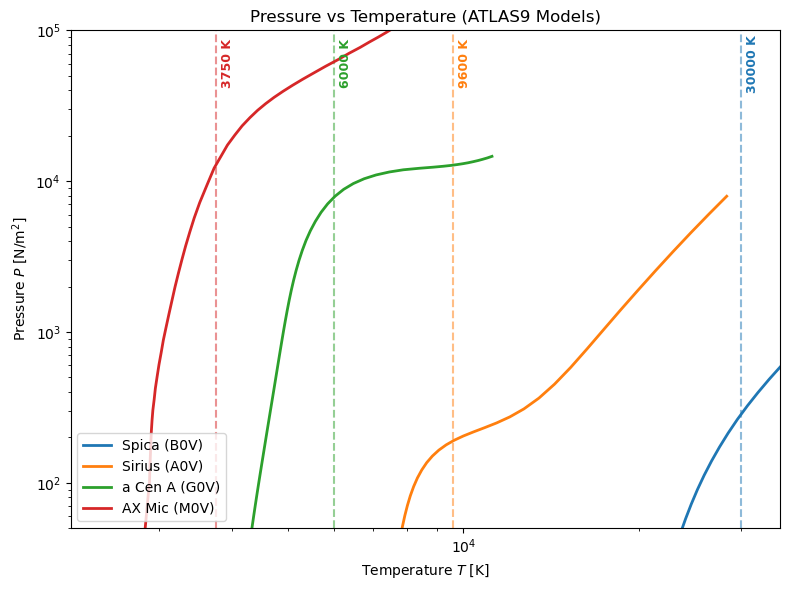

In [3]:
# Problem 2. 

# 1. Plot the model pressure P as a function of the temperature T for the 4 stars, in the same plot (label
# the curves). Use both log axis with 0 < T < 35, 000 K and 50 < P < 10^5 N/m2

def read_mod_file(filename):
    '''extracts T and P from an ATLAS9 .mod file and converts these from cgs to si units'''
    T_vals, P_vals = [], []
    with open(filename, 'r') as f:
        for line in f:
            # skipping comments
            if line.startswith('#'):
                continue 
            cols = line.split()
            # Column 2 is T in K; Column 3 is P in dynes/cm^2
            T_vals.append(float(cols[1]))
            # converting P to N/cm^2
            P_vals.append(float(cols[2]) / 10.0)  
    return T_vals, P_vals

# File paths for each star's .mod file
files = {
    'Spica (B0V)': 'B0V_T30000G400_2p00.mod.txt',
    'Sirius (A0V)': 'A0V_T09600G420_2p00r.mod.txt',
    'a Cen A (G0V)': 'G0V_T06000G440_2p00.mod.txt',
    'AX Mic (M0V)': 'M0V_T03750G450_2p00.mod.txt'
}
# Effective temperatures (in K)
T_eff_dict = {
    'Spica (B0V)': 30000,
    'Sirius (A0V)': 9600,
    'a Cen A (G0V)': 6000,
    'AX Mic (M0V)': 3750
}

plt.figure(figsize=(8, 6))

# Plot each model curve
for label, filepath in files.items():
    T, P = read_mod_file(filepath)
    line, = plt.plot(T, P, label=label, linewidth=2)
    color = line.get_color()
    target_T = T_eff_dict[label]
    plt.axvline(x=target_T, color = color, linestyle='--', alpha=0.5)
    plt.text(target_T * 1.02, 6e4, f'{target_T} K', color=color, 
             fontsize=9, fontweight='bold', rotation=90, verticalalignment='center')

# Set logarithmic axes and required ranges
plt.xscale('log')
plt.yscale('log')
plt.xlim(0, 35000)
plt.ylim(50, 1e5)

# Label axes with units
plt.xlabel('Temperature $T$ [K]')
plt.ylabel('Pressure $P$ [N/m$^2$]')
plt.title('Pressure vs Temperature (ATLAS9 Models)')
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()


In [4]:
#  Problem 3:
# 1. Load in the model spectra for Spica. Plot in the same window the model intensity H_ν and
# the continuum intensity H_cont. Use the logarithmic axis for the wavelength, and make sure the UV and
# visible spectral regions are shown. Mark on the plot the location of the first three lines of the Lyman
# and Balmer series


def read_spectrum(filename):
    '''extracts wavelength (nm), H_nu(model intensity), and H_cont(continuum intensity) from an ATLAS9 .flux file.'''
    wavelength_nm = []
    H_nu = []
    H_cont = []
    
    with open(filename, 'r') as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            cols = line.split()
            if cols[0] == 'FLUX':
                wavelength_nm.append(float(cols[2])) 
                H_nu.append(float(cols[3]))           
                H_cont.append(float(cols[4]))         
                
    return wavelength_nm, H_nu, H_cont

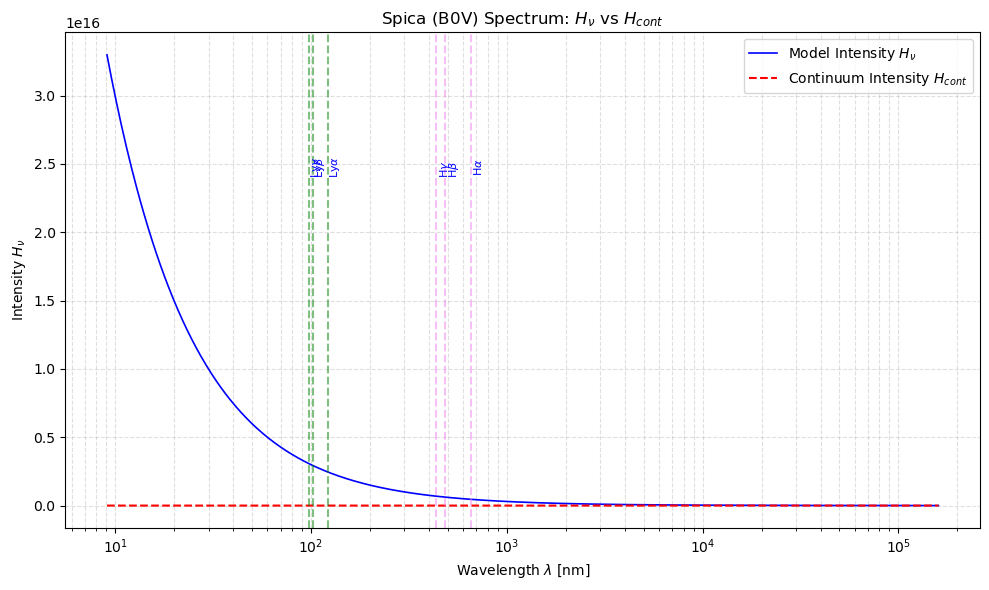

In [26]:
lam_spica, H_nu_spica, H_cont_spica = read_spectrum('B0V_T30000G400_2p00.flx.txt')

plt.figure(figsize=(10, 6))

# Plot H_nu and H_cont
plt.plot(lam_spica, H_nu_spica, label=r'Model Intensity $H_\nu$', color='blue', lw=1.2)
plt.plot(lam_spica, H_cont_spica, label=r'Continuum Intensity $H_{cont}$', color='red', linestyle='--', lw=1.5)

# First 3 Lymann Lines (nm)
lyman3 = {'Ly$\\alpha$': 122, 'Ly$\\beta$': 103, 'Ly$\\gamma$': 97.3}
for name, pos in lyman3.items():
    plt.axvline(x=pos, color='green', linestyle='--', alpha=0.5)
    plt.text(pos, plt.ylim()[1] * 0.7, name, color='blue', rotation=90, fontsize=8)
    
# First 3 Balmer Lines (nm)
balmer3 = {'H$\\alpha$': 656, 'H$\\beta$': 486, 'H$\\gamma$': 434}
for name, pos in balmer3.items():
    plt.axvline(x=pos, color='violet', linestyle='--', alpha=0.5)
    plt.text(pos + 10, plt.ylim()[1] * 0.7, name, color='blue', rotation=90, fontsize=8)

plt.xscale('log')
plt.xlabel(r'Wavelength $\lambda$ [nm]')
plt.ylabel(r'Intensity $H_\nu$')
plt.title('Spica (B0V) Spectrum: $H_\\nu$ vs $H_{cont}$')
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()



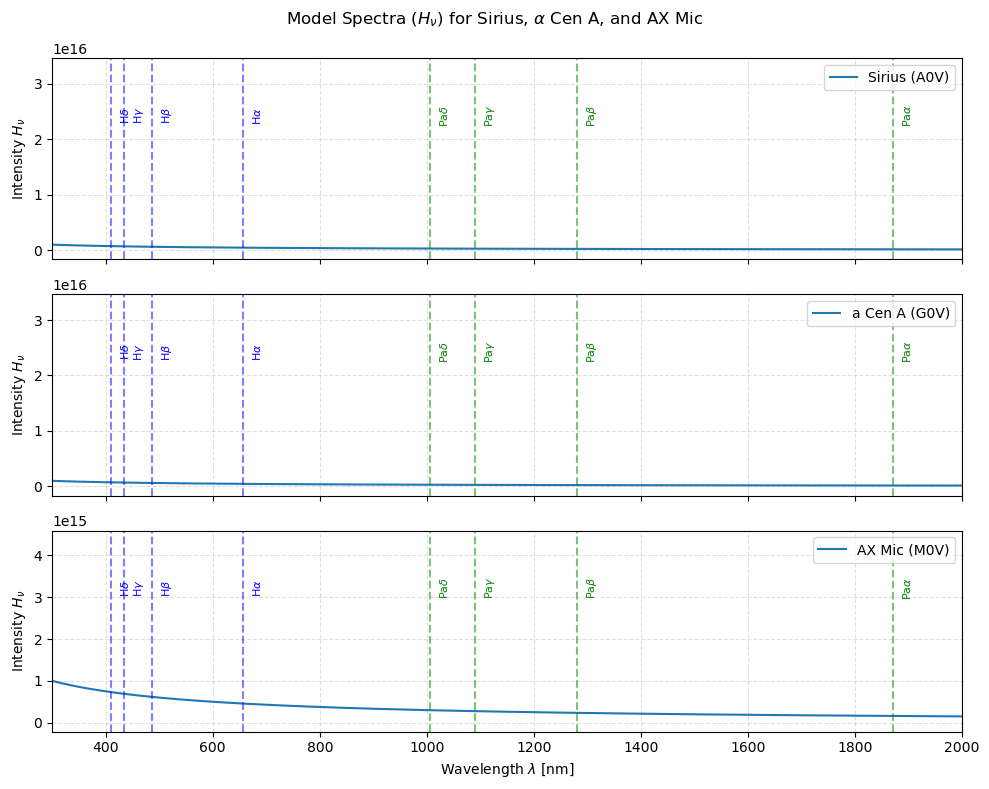

In [6]:
# Problem 3
# 3. Load in a new plotting window the model spectra (Hν) of the three remaining stars. Use linear scale
# in both axis and show the spectra up to λ ≃ 2 µm. Remember to label the spectra and the axis. Can
# you identify the first four H lines of the Paschen and Balmer series?

# File paths 
files_p3 = {
    'Sirius (A0V)': 'A0V_T09600G420_2p00r.flx.txt',
    'a Cen A (G0V)': 'G0V_T06000G440_2p00.flx.txt',
    'AX Mic (M0V)': 'M0V_T03750G450_2p00.flx.txt'
}

# Balmer lines (in nm)
balmer_lines = {
    'H$\\alpha$': 656, 
    'H$\\beta$': 486, 
    'H$\\gamma$': 434, 
    'H$\\delta$': 410
}

# Paschen lines (in nm)
paschen_lines = {
    'Pa$\\alpha$': 1870, 
    'Pa$\\beta$': 1280, 
    'Pa$\\gamma$': 1090, 
    'Pa$\\delta$': 1005
}

# Create 3 subplots sharing the same x-axis, each with a distinct y-axis
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Plot spectra on separate y-axes
for ax, (label, filepath) in zip(axes, files_p3.items()):
    lam, H_nu, _ = read_spectrum(filepath)
    ax.plot(lam, H_nu, label=label, linewidth=1.5)
    ax.set_ylabel(r'Intensity $H_\nu$')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper right')
    
    # Calculate text_y individually for each plot based on its specific y-axis range
    ymin, ymax = ax.get_ylim()
    text_y = ymax * 0.70

    # Draw Balmer series vertical lines and labels
    for name, pos in balmer_lines.items():
        ax.axvline(x=pos, color='blue', linestyle='--', alpha=0.5)
        ax.text(pos + 15, text_y, name, color='blue', rotation=90, verticalalignment='center', fontsize=8)

    # Draw Paschen series vertical lines and labels
    for name, pos in paschen_lines.items():
        ax.axvline(x=pos, color='green', linestyle='--', alpha=0.5)
        ax.text(pos + 15, text_y, name, color='green', rotation=90, verticalalignment='center', fontsize=8)

# Set common x-axis limit up to lambda ~ 2 mu m (= 2000 nm)
plt.xlim(300, 2000)

# Common x-label and main title
plt.xlabel(r'Wavelength $\lambda$ [nm]')
fig.suptitle(r'Model Spectra ($H_\nu$) for Sirius, $\alpha$ Cen A, and AX Mic', fontsize=12)

plt.tight_layout()
plt.show()

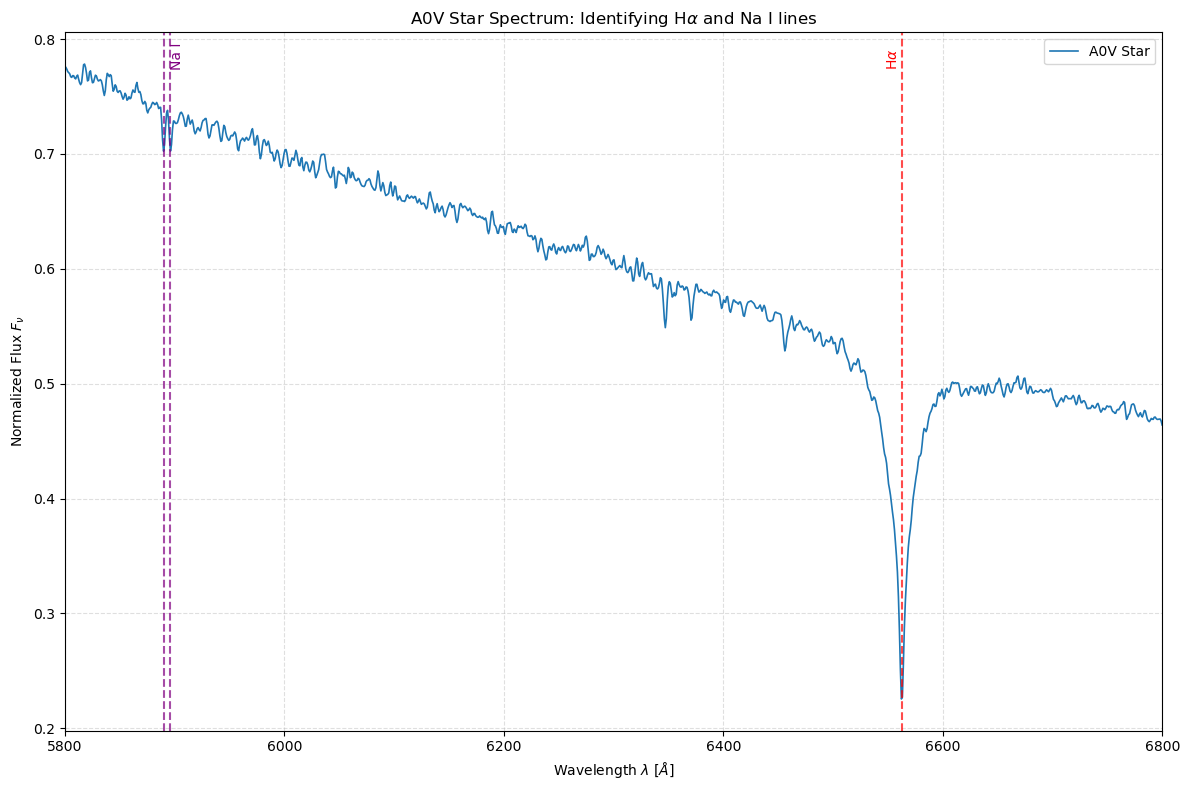

In [25]:
# Problem 4

# Download from the MILES library the spectra for one A0V and one G0V star. Load the two spectra
# , visualizing the wavelength interval between 5,800 and 6,800 A. You can either plot the two
# spectra individually, or as a “Stacked Lines Plot”.


# 1. Identify the Hα line and the two neutral sodium lines in both spectra. Hint: refer to the examples at
# the end of lecture 17 for lines identification.

# Spectra of A0V star
data = np.loadtxt('A0Vspectra.txt')

lam_a0v = data[:, 0]
flux_a0v = data[:, 1]

plt.figure(figsize=(12, 8))


plt.plot(lam_a0v, flux_a0v, label='A0V Star', color='tab:blue', linewidth=1.2)

plt.axvline(x=6563, color='red', linestyle='--', alpha=0.7)
plt.text(6563 - 15, 0.95, r'H$\alpha$', color='red', rotation=90, fontsize=10, transform=plt.gca().get_xaxis_transform())

plt.axvline(x=5890, color='purple', linestyle='--', alpha=0.7)
plt.axvline(x=5896, color='purple', linestyle='--', alpha=0.7)
plt.text(5896, 0.95, 'Na I', color='purple', rotation=90, fontsize=10, transform=plt.gca().get_xaxis_transform())

plt.xlim(5800, 6800)

plt.xlabel(r'Wavelength $\lambda$ [$\AA$]')
plt.ylabel(r'Normalized Flux $F_\nu$')

plt.title(r'A0V Star Spectrum: Identifying H$\alpha$ and Na I lines') 
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

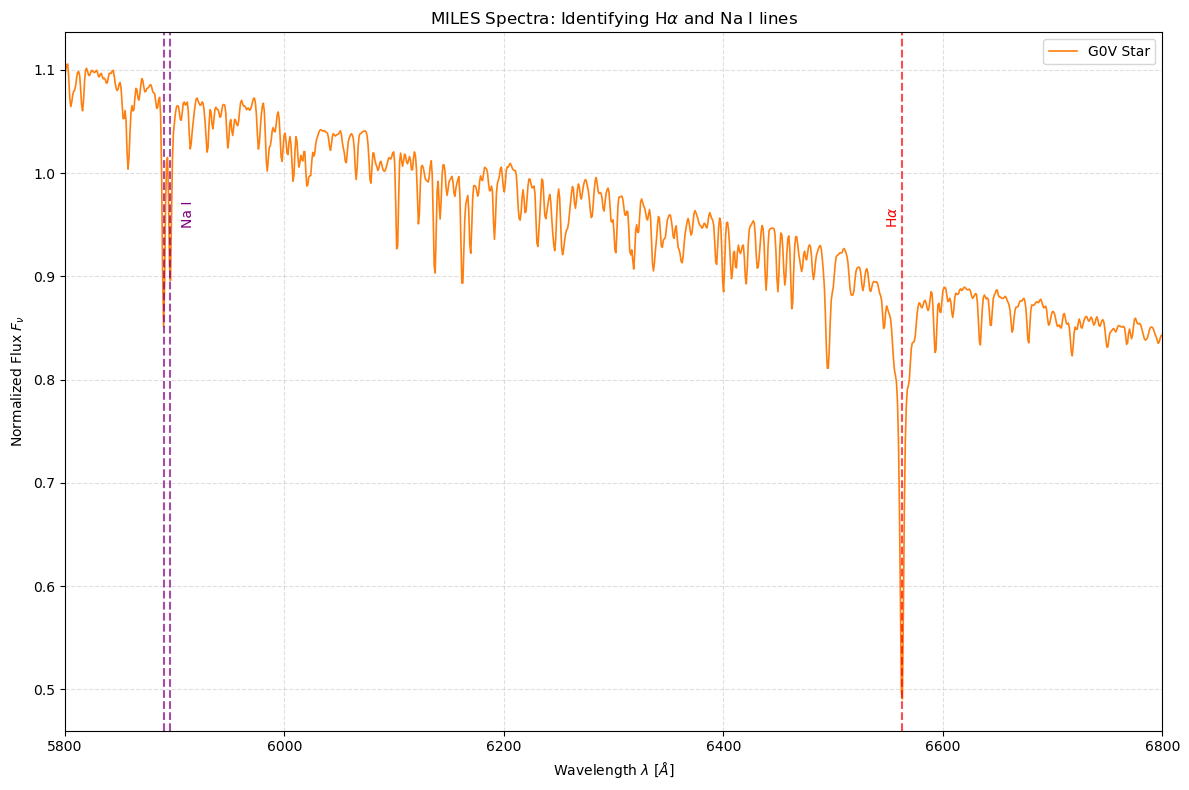

In [24]:
# Spectra of G0V star
data = np.loadtxt('G0Vspectra.txt')

lam_g0v = data[:, 0]
flux_g0v = data[:, 1]

plt.figure(figsize=(12, 8))

plt.plot(lam_g0v, flux_g0v, label='G0V Star', color='tab:orange', linewidth=1.2)

plt.axvline(x=6563, color='red', linestyle='--', alpha=0.7)
plt.text(6563 - 15, 0.95, r'H$\alpha$', color='red', rotation=90, fontsize=10)

plt.axvline(x=5890, color='purple', linestyle='--', alpha=0.7)
plt.axvline(x=5896, color='purple', linestyle='--', alpha=0.7)
plt.text(5896 + 10, 0.95, 'Na I', color='purple', rotation=90, fontsize=10)

plt.xlim(5800, 6800)

plt.xlabel(r'Wavelength $\lambda$ [$\AA$]')
plt.ylabel(r'Normalized Flux $F_\nu$')
plt.title(r'MILES Spectra: Identifying H$\alpha$ and Na I lines')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()